## Table of Contents
1. [Overview (v1.1.0 Feature Expansion)](#1-overview-v110-feature-expansion)
2. [Load Processed Data & Memory Optimization](#2-load-processed-data--memory-optimization)
3. [Train / Validation Split](#3-train--validation-split)
4. [Baseline XGBoost Model (All 68 Features)](#4-baseline-xgboost-model-all-68-features)
5. [Multi-Season Cross-Validation (Full 68 vs. Trimmed 62 Features)](#5-multi-season-cross-validation-full-68-vs-trimmed-62-features)
6. [Hyperparameter Optimization (Optuna)](#6-hyperparameter-optimization-optuna)
7. [Tuned XGBoost Model & Learning Curve](#7-tuned-xgboost-model--learning-curve)
8. [Model Explainability (SHAP Analysis)](#8-model-explainability-shap-analysis)
9. [Second Model Family: LightGBM & Optuna Tuning](#9-second-model-family-lightgbm--optuna-tuning)
10. [Tuned LightGBM Model & Learning Curve](#10-tuned-lightgbm-model--learning-curve)
11. [Model Ensembling (XGBoost + LightGBM Blend)](#11-model-ensembling-xgboost--lightgbm-blend)

In [1]:
import os
import shap
import optuna
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from IPython.display import Markdown, display
from sklearn.metrics import root_mean_squared_error

pd.set_option('display.max_columns', None)

# Dynamically resolve the data directory regardless of the active working directory
cwd = Path.cwd()
if (cwd / "data").exists():
    DATA_DIR = cwd / "data"
elif (cwd.parent / "data").exists():
    DATA_DIR = cwd.parent / "data"
else:
    DATA_DIR = cwd / "store-sales-forecasting" / "data"

PROCESSED_DIR = DATA_DIR / "processed" / "experiments"
print(f"Active Data Directory: {DATA_DIR.resolve()}")

Active Data Directory: /home/user/myprojects/store-sales-forecasting/data


## 1. Overview (v1.1.0 Feature Expansion)
In **v1.0.0**, we established our initial forecasting pipeline using 34 baseline features (31 after trimming), achieving a tuned validation RMSLE of `0.39358` with XGBoost. However, multi-season cross-validation revealed higher errors during sharp seasonal transitions: most notably in the Autumn / Back-to-School fold (`0.60449` untuned / `0.61764` tuned).

In **v1.1.0**, we expand the feature space to **68 engineered features** (excluding the redundant `is_holiday` and `is_earthquake_period` flags upfront) to capture richer temporal, promotional, and hierarchical dynamics:
* **Short-Term & Exponentially Weighted Sales Dynamics:** 7-day and 14-day rolling means/standard deviations and EWMs anchored at `lag16`, plus a 7-vs-28-day sales momentum indicator (`sales_log1p_momentum_7_28`).

* **Yearly Seasonal Lags:** 364-day lag features (`sales_log1p_lag364`, 7-day rolling mean and std) to align day-of-week annual seasonality.

* **Hierarchical Aggregations:** Store-level and state-by-family 7-day rolling sales averages (`store_sales_log1p_lag16_rolling_mean_7`, `state_family_sales_log1p_lag16_rolling_mean_7`).

* **Promotional & Footfall Dynamics:** Historical promotion lags (7, 16, 21), rolling promotion intensity, current-vs-historical promo differentials (`promo_diff_*`, `promo_rel_diff_*`), and expanded transaction lags/EWMs.

* **Macroeconomic (Oil Price) Momentum:** 28-day oil price rolling statistics, percentage deviation from the moving average, and point/trend momentum indicators.

### Modeling Workflow in v1.1.0
Since single-feature Leave-One-Out ablation is suboptimal across 68 highly correlated time-series features (where tree splits easily substitute one lag or rolling window for another), we streamline our evaluation workflow:
1. **Baseline Benchmark:** Train a default XGBoost model on all 68 features and compare directly against the v1.0.0 baseline (`0.40022`).

2. **Multi-Season Cross-Validation:** Evaluate the **Full 68-Feature Set** against a **Trimmed 62-Feature Set** (dropping all 6 oil-related features) across all 4 seasonal folds.

3. **Bayesian Optimization (Optuna) & Explainability:** Tune XGBoost and LightGBM on the locked feature set, verify learning curves and SHAP attributions, and blend both model families.

## 2. Load Processed Data & Memory Optimization
We load the expanded `train_features.parquet` dataset. Since doubling the feature space across ~2.9 million rows significantly increases memory pressure during histogram binning and hyperparameter tuning, we immediately drop non-feature columns (`id`, `sales`) and downcast all 64-bit numeric columns to `float32`, cutting RAM usage by ~50% while preserving native `category` types for XGBoost and LightGBM.

In [2]:
import gc

df_train_features = pd.read_parquet(PROCESSED_DIR / 'train_features.parquet')

# Drop unused columns immediately to save RAM
df_train_features = df_train_features.drop(columns=['id', 'sales'], errors='ignore')

# Convert all 64-bit floats AND nullable BigQuery Int64 columns to standard float32
cols_to_downcast = df_train_features.select_dtypes(include=['float64', 'int64', 'Int64']).columns
df_train_features[cols_to_downcast] = df_train_features[cols_to_downcast].astype(np.float32)

gc.collect()
display(df_train_features.head(5))

,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
0,2013-03-01,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,0,None,1921.0,1878.0,1806.0,1770.0,1126.714233,1332.142822,1431.857178,714.835083,619.147766,543.911926,1155.631836,2013,3,1,4,60,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,95.162498,1.963728,-0.046788,-0.069259,0.002204,1.098612,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839,0.584906,0.568968,0.627606,0.670171,0.388629,0.589055,-0.340790,NaN,NaN,0.0,2.247723,1.787368
1,2013-03-02,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,0,None,2119.0,1104.0,1377.0,1295.0,1182.714233,1361.571411,1443.750000,781.906982,647.478760,555.460205,1396.474487,2013,3,2,5,61,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.921425,2.081996,-0.044367,-0.069259,-0.001964,0.693147,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943941,0.696499,0.630545,0.485885,0.568968,0.661451,0.670171,0.291471,0.510388,-0.458055,NaN,NaN,0.0,2.258461,1.751521
2,2013-03-03,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,0,None,1787.0,374.0,531.0,542.0,1169.714233,1360.214233,1445.250000,769.071655,646.494690,556.359863,1494.105957,2013,3,3,6,62,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.680359,2.166254,-0.041934,-0.069259,-0.006118,1.098612,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517,0.328941,0.469947,0.620931,0.641938,0.218603,0.442242,-0.600519,NaN,NaN,0.0,2.246278,1.663145
3,2013-03-04,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.129997,0,None,1263.0,396.0,1714.0,1738.0,1192.428589,1352.071411,1440.750000,769.155334,646.984802,557.340332,1436.329468,2013,3,4,0,63,0,0,1,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.463211,2.307375,-0.045872,-0.063195,-0.009516,1.791759,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334,0.198042,0.519457,0.338221,0.629515,0.337239,0.475736,-0.692181,NaN,NaN,0.0,2.246379,1.651922
4,2013-03-05,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.879997,0,None,399.0,487.0,1775.0,1772.0,1196.000000,1342.642822,1436.892822,764.767273,660.687500,564.371216,1176.996826,2013,3,5,1,64,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.256073,2.360722,-0.035818,-0.059992,-0.012970,0.000000,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856,0.198042,0.568968,0.338221,0.612546,0.426216,0.504755,-0.667426,NaN,NaN,0.0,2.246239,1.671136


## 3. Train / Validation Split
Following the exact chronological validation setup from v1.0.0, we reserve the final 16 days of the training set (`2017-07-31` to `2017-08-15`) as our primary validation window (Fold 1) to mirror the 16-day test horizon.

Based on our v1.0.0 ablation findings, we exclude `is_holiday` and `is_earthquake_period` upfront in `IGNORE_COLS` (as their signal is fully captured by `holiday_name`), resulting in **68 active predictors** in `ALL_FEATURES`. All historical sales and transaction features remain strictly anchored at $\ge 16$ days in the past (or 364 days for annual lags) to guarantee zero data leakage.

In [3]:
FORECAST_HORIZON = 16

def split_train_dataset(
    df: pd.DataFrame, 
    feature_cols: list[str], 
    target_col: str = 'sales_log1p',
    val_start: str = '2017-07-31',
    val_days: int = FORECAST_HORIZON,
) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series]:
    """Splits data chronologically into train and validation sets."""
    start_dt = pd.to_datetime(val_start)
    end_dt = start_dt + pd.Timedelta(days=val_days-1)
    
    date_range_train = (df['date'] >= '2013-03-01') & (df['date'] < start_dt)
    date_range_validation = (df['date'] >= start_dt) & (df['date'] <= end_dt)
    
    X_train = (df.loc[date_range_train, feature_cols]).reset_index(drop=True)
    y_train = (df.loc[date_range_train, target_col]).reset_index(drop=True)

    X_valid = (df.loc[date_range_validation, feature_cols]).reset_index(drop=True)
    y_valid = (df.loc[date_range_validation, target_col]).reset_index(drop=True)

    return X_train, y_train, X_valid, y_valid


IGNORE_COLS = ['id', 'date', 'sales', 'sales_log1p', 'is_holiday', 'is_earthquake_period']
ALL_FEATURES = [col for col in df_train_features.columns if col not in IGNORE_COLS]

X_train, y_train, X_valid, y_valid = split_train_dataset(
    df = df_train_features, 
    feature_cols = ALL_FEATURES, 
    target_col = 'sales_log1p',
    val_start = '2017-07-31'
)

#del df_train_features
#gc.collect()

display(
    X_train.head(5),
    Markdown('---'),
    y_train.head(5),
    Markdown('---'),
    X_valid.head(5),
    Markdown('---'),
    y_valid.head(5),
)

,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
0,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,None,1921.0,1878.0,1806.0,1770.0,1126.714233,1332.142822,1431.857178,714.835083,619.147766,543.911926,1155.631836,2013,3,1,4,60,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,95.162498,1.963728,-0.046788,-0.069259,0.002204,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839,0.584906,0.568968,0.627606,0.670171,0.388629,0.589055,-0.340790,NaN,NaN,0.0,2.247723,1.787368
1,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,None,2119.0,1104.0,1377.0,1295.0,1182.714233,1361.571411,1443.750000,781.906982,647.478760,555.460205,1396.474487,2013,3,2,5,61,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.921425,2.081996,-0.044367,-0.069259,-0.001964,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943941,0.696499,0.630545,0.485885,0.568968,0.661451,0.670171,0.291471,0.510388,-0.458055,NaN,NaN,0.0,2.258461,1.751521
2,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.709999,None,1787.0,374.0,531.0,542.0,1169.714233,1360.214233,1445.250000,769.071655,646.494690,556.359863,1494.105957,2013,3,3,6,62,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.680359,2.166254,-0.041934,-0.069259,-0.006118,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517,0.328941,0.469947,0.620931,0.641938,0.218603,0.442242,-0.600519,NaN,NaN,0.0,2.246278,1.663145
3,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.129997,None,1263.0,396.0,1714.0,1738.0,1192.428589,1352.071411,1440.750000,769.155334,646.984802,557.340332,1436.329468,2013,3,4,0,63,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.463211,2.307375,-0.045872,-0.063195,-0.009516,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334,0.198042,0.519457,0.338221,0.629515,0.337239,0.475736,-0.692181,NaN,NaN,0.0,2.246379,1.651922
4,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,90.879997,None,399.0,487.0,1775.0,1772.0,1196.000000,1342.642822,1436.892822,764.767273,660.687500,564.371216,1176.996826,2013,3,5,1,64,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.256073,2.360722,-0.035818,-0.059992,-0.012970,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856,0.198042,0.568968,0.338221,0.612546,0.426216,0.504755,-0.667426,NaN,NaN,0.0,2.246239,1.671136


---

0    1.098612
1    0.693147
2    1.098612
3    1.791759
4    0.000000
Name: sales_log1p, dtype: float32

---

,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,holiday_name,transactions_lag16,transactions_lag21,transactions_lag28,transactions_lag35,transactions_lag16_rolling_mean_7,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_7,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,transactions_lag16_ewm_mean_7,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,onpromotion_lag7,onpromotion_lag16,onpromotion_lag21,onpromotion_rolling_mean_7,onpromotion_rolling_std_7,onpromotion_rolling_mean_14,onpromotion_rolling_std_14,promo_diff_lag7,promo_diff_lag16,promo_diff_lag21,promo_diff_mean_7,promo_rel_diff_mean_7,promo_rel_diff_mean_14,oil_price_rolling_mean_28,oil_price_rolling_std_28,oil_price_dev_ma28_pct,oil_price_point_mom_pct,oil_price_trend_mom_pct,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28,sales_log1p_lag16_rolling_mean_7,sales_log1p_lag16_rolling_mean_14,sales_log1p_lag16_rolling_std_7,sales_log1p_lag16_rolling_std_14,sales_log1p_lag16_ewm_mean_7,sales_log1p_lag16_ewm_mean_14,sales_log1p_momentum_7_28,sales_log1p_lag364,sales_log1p_lag364_rolling_mean_7,sales_log1p_lag364_rolling_std_7,store_sales_log1p_lag16_rolling_mean_7,state_family_sales_log1p_lag16_rolling_mean_7
0,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,50.209999,None,1338.0,1814.0,1890.0,1752.0,1572.428589,1575.857178,1560.142822,481.592804,468.615112,454.771149,1617.291138,2017,7,31,0,212,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.591427,1.778476,0.077666,0.091047,0.039167,1.945910,1.386294,0.000000,1.386294,0.924196,1.420850,1.466912,0.651051,0.584670,1.785960,1.567370,0.433607,0.615880,1.834492,1.715852,0.319049,1.386294,1.466876,0.755353,3.622671,1.979719
1,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,49.189999,None,518.0,1760.0,1803.0,1764.0,1563.714233,1574.142822,1558.035767,502.655853,472.714081,459.606140,1342.468384,2017,8,1,1,213,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.704643,1.840567,0.053214,0.068883,0.043446,1.098612,2.079442,1.791759,1.609438,1.826880,1.454422,1.477186,0.673263,0.593057,1.785960,1.530882,0.433607,0.628205,1.650522,1.633553,0.308775,2.397895,1.579513,0.834767,3.614773,1.985753
2,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,49.599998,None,1739.0,1970.0,1913.0,1906.0,1553.000000,1563.357178,1557.750000,497.201508,466.636505,459.486786,1441.601196,2017,8,2,2,214,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.865002,1.891381,0.058359,0.099534,0.047605,1.098612,2.079442,0.693147,1.098612,1.290400,1.524481,1.487460,0.684331,0.601146,1.744863,1.609354,0.488020,0.471281,1.512545,1.562228,0.257403,0.000000,1.579513,0.834767,3.599837,2.020654
3,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,49.029999,None,1733.0,1679.0,1698.0,1645.0,1549.142822,1558.357178,1556.142822,495.429596,464.240082,458.766022,1514.450928,2017,8,3,3,215,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.990356,1.915105,0.043406,0.077109,0.050542,1.386294,2.302585,1.791759,0.693147,1.595831,1.639441,1.520185,0.668944,0.620076,1.645842,1.580393,0.479057,0.471668,1.480982,1.538770,0.125657,1.386294,1.579513,0.834767,3.607517,2.032993
4,1,AUTOMOTIVE,0.0,Quito,Pichincha,D,13,49.570000,None,1797.0,1867.0,1843.0,1852.0,1524.428589,1550.071411,1554.571411,474.822723,458.422302,457.828552,1585.088257,2017,8,4,4,216,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,47.180359,1.896977,0.050649,0.120226,0.056113,2.079442,1.609438,1.609438,2.484907,1.901261,1.576908,1.520185,0.623184,0.620076,1.645842,1.679414,0.479057,0.412934,1.630597,1.610860,0.125657,1.791759,1.521589,0.798019,3.573513,2.060370


---

0    2.197225
1    1.791759
2    1.609438
3    1.386294
4    2.197225
Name: sales_log1p, dtype: float32

## 4. Baseline XGBoost Model (All 68 Features)
We first train an untuned `XGBRegressor` (`tree_method='hist'`, `learning_rate=0.05`, `max_depth=6`, `early_stopping_rounds=50`) using all 68 features to measure the immediate lift over our v1.0.0 baseline (`0.40022`).

In [4]:
def train_evaluate_xgboost(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_valid: pd.DataFrame,
    y_valid: pd.Series,
    params: dict = None,
    verbose: int = 20,
    model_path: Path = None,
) -> tuple[xgb.XGBRegressor, float, pd.Series]:
    """Train (or load from disk) an XGBoost regressor using a configuration dict and evaluate validation RMSLE on sales, i.e. RMSE on log(1+sales)."""

    history_path = (model_path.with_name(f'{model_path.stem}_history.csv') if model_path else None)

    # --- 1. CASE: CACHE EXISTS (Load model + learning history & replay exact console logs) ---
    if model_path and model_path.exists() and history_path.exists():
        print(f'Loading cached model from {model_path}...\n')
        model = xgb.XGBRegressor(enable_categorical=True)
        model.load_model(model_path)

        hist_df = pd.read_csv(history_path)
        train_rmse_list = hist_df['train_rmse'].tolist()
        val_rmse_list = hist_df['val_rmse'].tolist()
        best_iter = int(hist_df['best_iteration'].iloc[0])

        if verbose:
            step = int(verbose) if isinstance(verbose, int) and verbose > 0 else 20
            for i in range(len(train_rmse_list)):
                if i % step == 0 or i == len(train_rmse_list) - 1:
                    print(f'[{i}]\tvalidation_0-rmse:{train_rmse_list[i]:.5f}\tvalidation_1-rmse:{val_rmse_list[i]:.5f}')

        raw_preds = model.predict(X_valid, iteration_range=(0, best_iter + 1))
    
    # --- 2. CASE: NO CACHE (Train from scratch and save both model & history) ---
    else:
        default_config = {
            'tree_method': 'hist',
            'enable_categorical': True,
            'random_state': 42,
            'n_jobs': 4,
            'n_estimators': 1500,
            'learning_rate': 0.05,
            'early_stopping_rounds': 50,
            'eval_metric': 'rmse',
            'max_depth': 6,
            'min_child_weight': 1,
            'subsample': 1.0,
            'colsample_bytree': 1.0,
            'reg_alpha': 0.0,
            'reg_lambda': 1.0,
        }

        if params:
            default_config.update(params)

        model = xgb.XGBRegressor(**default_config)

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_train, y_train), (X_valid, y_valid)],
            verbose=verbose
        )

        evals_res = model.evals_result()
        train_rmse_list = evals_res['validation_0']['rmse']
        val_rmse_list = evals_res['validation_1']['rmse']
        best_iter = getattr(model, 'best_iteration', None)
        if best_iter is None:
            best_iter = len(train_rmse_list) - 1

        if model_path:
            os.makedirs(model_path.parent, exist_ok=True)
            model.save_model(model_path)
            pd.DataFrame({
                'train_rmse': train_rmse_list,
                'val_rmse': val_rmse_list,
                'best_iteration': best_iter,
            }).to_csv(history_path, index=False)
            print(f'Model and its history saved to {model_path}')

        raw_preds = model.predict(X_valid)

    preds_valid = pd.Series(
        np.clip(raw_preds, 0, None),
        index=X_valid.index,
        name='preds_log1p',
    )

    val_rmsle = root_mean_squared_error(y_valid, preds_valid)

    if verbose:
        iter_label = (
            f'Best Iteration: {best_iter}' if getattr(model, 'best_iteration', None) is not None else f'Total Trees: {len(train_rmse_list)}'
        )
        print(f'\n--- Validation RMSLE: {val_rmsle:.5f} ({iter_label}) ---')

    return model, val_rmsle, preds_valid

# Train (or load) Baseline XGBoost model with all 68 features
baseline_model, baseline_rmsle, baseline_preds = train_evaluate_xgboost(
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid,
    model_path=PROCESSED_DIR / 'baseline_xgb_model.json',
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/experiments/baseline_xgb_model.json...

[0]	validation_0-rmse:2.56907	validation_1-rmse:2.49069
[20]	validation_0-rmse:1.09751	validation_1-rmse:0.99519
[40]	validation_0-rmse:0.67027	validation_1-rmse:0.54200
[60]	validation_0-rmse:0.55956	validation_1-rmse:0.44028
[80]	validation_0-rmse:0.51780	validation_1-rmse:0.41895
[100]	validation_0-rmse:0.49233	validation_1-rmse:0.41412
[120]	validation_0-rmse:0.47882	validation_1-rmse:0.41202
[140]	validation_0-rmse:0.46666	validation_1-rmse:0.41118
[160]	validation_0-rmse:0.45678	validation_1-rmse:0.41039
[180]	validation_0-rmse:0.44890	validation_1-rmse:0.40964
[200]	validation_0-rmse:0.44326	validation_1-rmse:0.40894
[220]	validation_0-rmse:0.43826	validation_1-rmse:0.40864
[240]	validation_0-rmse:0.43424	validation_1-rmse:0.40779
[260]	validation_0-rmse:0.43038	validation_1-rmse:0.40728
[280]	validation_0-rmse:0.42724	validation_1-rmse:0.40672
[300]	val

**Baseline Result (`0.39469` at Iteration `1142`):** Expanding from 34 to 68 features reduces untuned validation RMSLE from `0.40022` (v1.0.0) to **`0.39469` (`-1.38%`)** while converging in `1,142` trees instead of `1,389`. Notably, this untuned 68-feature baseline already outperforms the 31-feature trimmed baseline from v1.0.0 (`0.39767`).

## 5. Multi-Season Cross-Validation (Full 68 vs. Trimmed 62 Features)
In v1.0.0, dropping the raw `oil_price` column slightly improved generalization across seasonal folds. In v1.1.0, however, we engineered 5 additional oil momentum and moving-average deviation features (`oil_price_rolling_mean_28`, `oil_price_rolling_std_28`, `oil_price_dev_ma28_pct`, `oil_price_point_mom_pct`, `oil_price_trend_mom_pct`).

To test whether the expanded oil feature group provides useful macroeconomic regime context or still introduces noise, we evaluate two configurations across our 4 seasonal 16-day validation windows:
1. **Full Baseline (68 Features):** Retains all engineered features, including the 6 oil price indicators.

2. **Trimmed Model (62 Features):** Excludes all 6 oil-related features (`EXCLUDE_FEATURES`).

In [5]:
EXCLUDE_FEATURES = {'oil_price', 'oil_price_rolling_mean_28', 'oil_price_rolling_std_28', 'oil_price_dev_ma28_pct', 'oil_price_point_mom_pct', 'oil_price_trend_mom_pct'}
TRIMMED_FEATURES = [col for col in ALL_FEATURES if col not in EXCLUDE_FEATURES]

print(f'ALL FEATURES ({len(ALL_FEATURES)}) = {ALL_FEATURES}\n')
print(f'TRIMMED FEATURES ({len(TRIMMED_FEATURES)}) = {TRIMMED_FEATURES}')

ALL FEATURES (68) = ['store_nbr', 'family', 'onpromotion', 'city', 'state', 'store_type', 'cluster', 'oil_price', 'holiday_name', 'transactions_lag16', 'transactions_lag21', 'transactions_lag28', 'transactions_lag35', 'transactions_lag16_rolling_mean_7', 'transactions_lag16_rolling_mean_14', 'transactions_lag16_rolling_mean_28', 'transactions_lag16_rolling_std_7', 'transactions_lag16_rolling_std_14', 'transactions_lag16_rolling_std_28', 'transactions_lag16_ewm_mean_7', 'year', 'month', 'dayofmonth', 'dayofweek', 'dayofyear', 'is_nyd', 'is_christmas', 'is_month_start_end', 'is_mid_payday', 'onpromotion_lag7', 'onpromotion_lag16', 'onpromotion_lag21', 'onpromotion_rolling_mean_7', 'onpromotion_rolling_std_7', 'onpromotion_rolling_mean_14', 'onpromotion_rolling_std_14', 'promo_diff_lag7', 'promo_diff_lag16', 'promo_diff_lag21', 'promo_diff_mean_7', 'promo_rel_diff_mean_7', 'promo_rel_diff_mean_14', 'oil_price_rolling_mean_28', 'oil_price_rolling_std_28', 'oil_price_dev_ma28_pct', 'oil_pri

In [6]:
def run_cross_validation(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    all_features: list[str] = ALL_FEATURES,
    trimmed_features: list[str] = TRIMMED_FEATURES,
    params: dict = None,
    output_dir: Path = PROCESSED_DIR
) -> pd.DataFrame:
    """Performs Multi-Season Cross-Validation across distinct forecasting windows.
    Evaluates two configurations: Full Baseline (34) and Trimmed Features (31).
    Caches results to CSV for instant replay on subsequent runs."""

    configurations = {
        f'Full Baseline ({len(all_features)})': all_features,
        f'Trimmed ({len(trimmed_features)})': trimmed_features,
    }

    csv_path = output_dir / 'cross_validation_results.csv'
    os.makedirs(output_dir, exist_ok=True)
    
#   --- 1. CASE: CACHE EXISTS (Instant Replay identical to fresh run) ---
    if csv_path.exists():
        print(f'Found cached CV results in {csv_path}. Loading...\n')
        cv_df = pd.read_csv(csv_path)

        print(
            f'Starting Multi-Season Cross-Validation ({len(cv_windows)} Folds x {len(configurations)} Models = {len(cv_windows)*len(configurations)} fits)...\n'
        )

        for fold_name, group in cv_df.groupby('fold', sort=False):
            start_date = group['val_start'].iloc[0]
            print(f'=== {fold_name} | Val Start: {start_date} ===')
            for _, row in group.iterrows():
                print(
                    f"{row['fold']:<28} | {row['configuration']:<20} | Train RMSLE: {row['train_rmsle']:.5f} | Val RMSLE:  {row['val_rmsle']:.5f} | Iter: {int(row['best_iteration'])}"
                )
            print()

        return cv_df
    
    # --- 2. CASE: NO CACHE (Run the full cross-validation loop) ---

    records = []  

    print(
        f'Starting Multi-Season Cross-Validation ({len(cv_windows)} Folds x {len(configurations)} Models = {len(cv_windows)*len(configurations)} fits)...\n'
    )

    for fold_name, start_date in cv_windows.items():
        print(f'=== {fold_name} | Val Start: {start_date} ===')
        for config_name, feature_list in configurations.items(): 
            X_train, y_train, X_valid, y_valid = split_train_dataset(
                df=df,
                feature_cols=feature_list,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16
            )

            # Fit baseline model and extract RMSLE
            model, val_rmsle, _ = train_evaluate_xgboost(
                X_train=X_train,
                y_train=y_train,
                X_valid=X_valid,
                y_valid=y_valid,
                params=params,
                verbose=0
            )

            train_rmsle = model.evals_result()['validation_0']['rmse'][model.best_iteration]

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'configuration': config_name,
                'n_features': len(feature_list),
                'train_rmsle': train_rmsle,
                'val_rmsle': val_rmsle,
                'best_iteration': model.best_iteration,
            })

            print(
                f'{fold_name:<28} | {config_name:<20} | Train RMSLE: {train_rmsle:.5f} | Val RMSLE: {val_rmsle:.5f} | Iter: {model.best_iteration}'
            )

        print()     

    cv_df = pd.DataFrame(records)
    cv_df.to_csv(csv_path, index=False)
    print(f'Cross-validation results successfully saved to {csv_path}\n')  

    return cv_df    


CV_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
    'Fold 2 (Spring / Easter)': '2017-04-05',
    'Fold 3 (Winter / Christmas)': '2016-12-19',
    'Fold 4 (Autumn / Back-to-School)': '2016-09-01'
}

cv_df = run_cross_validation(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    all_features=ALL_FEATURES,
    trimmed_features=TRIMMED_FEATURES,
    params=None,
    output_dir = PROCESSED_DIR
)

summary_table = cv_df.pivot(
    index='fold', columns='configuration', values='val_rmsle'
)

display(cv_df)
display(Markdown('---'))
display(summary_table.round(5))

Found cached CV results in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/cross_validation_results.csv. Loading...

Starting Multi-Season Cross-Validation (4 Folds x 2 Models = 8 fits)...

=== Fold 1 (Summer Baseline) | Val Start: 2017-07-31 ===
Fold 1 (Summer Baseline)     | Full Baseline (68)   | Train RMSLE: 0.37786 | Val RMSLE:  0.39469 | Iter: 1142
Fold 1 (Summer Baseline)     | Trimmed (62)         | Train RMSLE: 0.44486 | Val RMSLE:  0.40432 | Iter: 266

=== Fold 2 (Spring / Easter) | Val Start: 2017-04-05 ===
Fold 2 (Spring / Easter)     | Full Baseline (68)   | Train RMSLE: 0.46879 | Val RMSLE:  0.45337 | Iter: 142
Fold 2 (Spring / Easter)     | Trimmed (62)         | Train RMSLE: 0.46981 | Val RMSLE:  0.45283 | Iter: 179

=== Fold 3 (Winter / Christmas) | Val Start: 2016-12-19 ===
Fold 3 (Winter / Christmas)  | Full Baseline (68)   | Train RMSLE: 0.46008 | Val RMSLE:  1.24082 | Iter: 148
Fold 3 (Winter / Christmas)  | Trimmed (62)         | Train RMS

,fold,val_start,configuration,n_features,train_rmsle,val_rmsle,best_iteration
0,Fold 1 (Summer Baseline),2017-07-31,Full Baseline (68),68,0.377860,0.394693,1142
1,Fold 1 (Summer Baseline),2017-07-31,Trimmed (62),62,0.444865,0.404321,266
2,Fold 2 (Spring / Easter),2017-04-05,Full Baseline (68),68,0.468791,0.453370,142
3,Fold 2 (Spring / Easter),2017-04-05,Trimmed (62),62,0.469813,0.452833,179
4,Fold 3 (Winter / Christmas),2016-12-19,Full Baseline (68),68,0.460079,1.240823,148
5,Fold 3 (Winter / Christmas),2016-12-19,Trimmed (62),62,0.463075,1.191491,175
6,Fold 4 (Autumn / Back-to-School),2016-09-01,Full Baseline (68),68,0.393354,0.537159,540
7,Fold 4 (Autumn / Back-to-School),2016-09-01,Trimmed (62),62,0.446096,0.532521,216


---

configuration,Full Baseline (68),Trimmed (62)
fold,,
Fold 1 (Summer Baseline),0.39469,0.40432
Fold 2 (Spring / Easter),0.45337,0.45283
Fold 3 (Winter / Christmas),1.24082,1.19149
Fold 4 (Autumn / Back-to-School),0.53716,0.53252


In [7]:
# Load or recreate training for Fold 3 (Winter / Christmas)

fold3_cache_path = PROCESSED_DIR / 'fold3_winter_analysis.csv'

if fold3_cache_path.exists():
  print(f'Found cached Fold 3 analysis in {fold3_cache_path}. Loading...\n')
  f3_res = pd.read_csv(fold3_cache_path).iloc[0]
  total_rmsle_all = f3_res['total_rmsle_all']
  rmsle_open_days_all = f3_res['rmsle_open_days_all']
  total_rmsle_trimmed = f3_res['total_rmsle_trimmed']
  rmsle_open_days_trimmed = f3_res['rmsle_open_days_trimmed']
else:
    X_train_f3_trimmed, y_train_f3_trimmed, X_valid_f3_trimmed, y_valid_f3_trimmed = split_train_dataset(
        df=df_train_features,
        feature_cols=TRIMMED_FEATURES,
        target_col='sales_log1p',
        val_start='2016-12-19',
        val_days=16,
    )
    model_f3_trimmed, _, preds_f3_trimmed = train_evaluate_xgboost(
        X_train=X_train_f3_trimmed,
        y_train=y_train_f3_trimmed,
        X_valid=X_valid_f3_trimmed,
        y_valid=y_valid_f3_trimmed,
        verbose=0   
    )

    X_train_f3_all, y_train_f3_all, X_valid_f3_all, y_valid_f3_all = split_train_dataset(
        df=df_train_features,
        feature_cols=ALL_FEATURES,
        target_col='sales_log1p',
        val_start='2016-12-19',
        val_days=16,
    )
    model_f3_all, _, preds_f3_all = train_evaluate_xgboost(
        X_train=X_train_f3_all,
        y_train=y_train_f3_all,
        X_valid=X_valid_f3_all,
        y_valid=y_valid_f3_all,
        verbose=0
    )

    mask_fold3 = (
        (df_train_features['date'] >= '2016-12-19') & (df_train_features['date'] <= '2017-01-03')
    )
    df_val_f3 = df_train_features.loc[mask_fold3].reset_index(drop=True)

    # Total RMSLE 
    total_rmsle_all = root_mean_squared_error(y_valid_f3_all, preds_f3_all)
    total_rmsle_trimmed = root_mean_squared_error(y_valid_f3_trimmed, preds_f3_trimmed)

    # RMSLE excluding Dec 25 and Jan 1
    closed_dates = pd.to_datetime(['2016-12-25', '2017-01-01'])
    open_days_mask = ~df_val_f3['date'].isin(closed_dates)

    rmsle_open_days_all = root_mean_squared_error(
        y_valid_f3_all[open_days_mask], preds_f3_all[open_days_mask]
    )
    rmsle_open_days_trimmed = root_mean_squared_error(
        y_valid_f3_trimmed[open_days_mask], preds_f3_trimmed[open_days_mask]
    )

    pd.DataFrame([{
      'total_rmsle_all': total_rmsle_all,
      'rmsle_open_days_all': rmsle_open_days_all,
      'total_rmsle_trimmed': total_rmsle_trimmed,
      'rmsle_open_days_trimmed': rmsle_open_days_trimmed,
    }]).to_csv(fold3_cache_path, index=False)

    print(f'Fold 3 results successfully saved to {fold3_cache_path}')

print('=== ALL FEATURES (68) ===')
print(f'Total RMSLE (16 days): {total_rmsle_all:.5f}')
print(f'RMSLE excluding Dec 25 and Jan 1 (14 days): {rmsle_open_days_all:.5f}')
display(Markdown('---'))
print('=== TRIMMED FEATURES (62) ===')
print(f'Total RMSLE (16 days): {total_rmsle_trimmed:.5f}')
print(f'RMSLE excluding Dec 25 and Jan 1 (14 days): {rmsle_open_days_trimmed:.5f}')

Found cached Fold 3 analysis in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/fold3_winter_analysis.csv. Loading...

=== ALL FEATURES (68) ===
Total RMSLE (16 days): 1.24082
RMSLE excluding Dec 25 and Jan 1 (14 days): 0.49854


---

=== TRIMMED FEATURES (62) ===
Total RMSLE (16 days): 1.19149
RMSLE excluding Dec 25 and Jan 1 (14 days): 0.51284


### What the Cross-Validation Results Tell Us

1. **Major Seasonal Generalization Gains Over v1.0.0:**  
   Doubling the feature space dramatically improves performance during difficult seasonal transitions:
   * **Autumn / Back-to-School (Fold 4):** Validation RMSLE drops from `0.62889` (v1.0.0 Full) / `0.60449` (v1.0.0 Trimmed) down to **`0.53716` (Full 68)** and **`0.53252` (Trimmed 62)**: an error reduction of **~12% to 14.6%**. The new 7-day rolling/EWM sales signals, 364-day annual lags, and hierarchical aggregations effectively capture the September demand shift.

   * **Winter Open Days (Fold 3 excluding Dec 25 & Jan 1):** Open-day RMSLE improves from `0.56559` (v1.0.0 Full) / `0.51673` (v1.0.0 Trimmed) down to **`0.49854` (Full 68)** and **`0.51284` (Trimmed 62)**.
   
   * **Summer Baseline (Fold 1):** Improves from `0.40022` (v1.0.0 Full) to **`0.39469` (Full 68)**.

2. **Full Baseline (68) vs. Trimmed (62) — Why Engineered Oil Features Now Help:**  
   Unlike v1.0.0 where raw `oil_price` alone added slight noise, removing the 6-feature oil block in v1.1.0 causes a sharp degradation in **Fold 1 (Summer)** (`0.39469` $\rightarrow$ `0.40432`), where early stopping halts training prematurely at iteration `266` (vs. `1,142` for Full 68). Full (68) also outperforms Trimmed (62) on **Winter open days** (`0.49854` vs. `0.51284`), while Spring (`0.45337` vs. `0.45283`) and Autumn (`0.53716` vs. `0.53252`) remain virtually tied. The oil rolling statistics and momentum indicators provide useful macroeconomic regime context that stabilizes deep tree growth.

**Conclusion:** We lock in **`ALL_FEATURES` (68 features)** as our final feature set for hyperparameter optimization.

## 6. Hyperparameter Optimization (Optuna)
With **`ALL_FEATURES` (68 features)** locked in, we run Bayesian Optimization via Optuna's **Tree-structured Parzen Estimator (TPE)** across **30 trials** (`6` random startup trials) on Fold 1 (`2017-07-31` to `2017-08-15`), backed by SQLite storage for trial persistence.

We jointly tune tree complexity (`max_depth` in `[4, 10]`, `min_child_weight` in `[1, 200]`), stochastic subsampling (`subsample` and `colsample_bytree` in `[0.5, 1.0]`), L1/L2 penalties (`reg_alpha`, `reg_lambda` in $[10^{-3}, 10^{1}]$), and `learning_rate` (`[0.025, 0.08]` with `n_estimators = 3000` and `early_stopping_rounds = 50`).

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
import gc

def run_optuna_tuning_xgboost(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    feature_cols: list[str] = ALL_FEATURES,  
    n_trials: int = 30,
    n_startup_trials: int = 6,
    seed: int = 42,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict, float]:
    """Runs hyperparameter tuning using Optuna across specified CV fold(s).
    Uses SQLite storage for live trial persistence and caches final results to CSV.
    """
    csv_path = output_dir / 'optuna_study_results_xgb.csv'
    os.makedirs(output_dir, exist_ok=True)

    # --- 1. CASE: CACHE EXISTS (Instant Replay) ---
    if csv_path.exists():
        print(f'Found cached Optuna results in {csv_path}. Loading without retraining...\n')
        study_df = pd.read_csv(csv_path)

        print(f'Replaying {len(study_df)} cached trials for folds: {list(cv_windows.keys())}...\n')
        for _, row in study_df.iterrows():
            print(
                f"Trial {int(row['trial_number']):02d} | "
                f"lr: {row['learning_rate']:.5f}, depth: {int(row['max_depth'])}, "
                f"min_child: {int(row['min_child_weight']):3d}, "
                f"sub: {row['subsample']:.5f}, col: {row['colsample_bytree']:.5f}, "
                f"reg_alpha: {row['reg_alpha']:.5f}, reg_lambda: {row['reg_lambda']:.5f} | "
                f"Mean Val RMSLE: {row['val_rmsle']:.5f}"
            )

        best_row = study_df.loc[study_df['val_rmsle'].idxmin()]
        best_value = best_row['val_rmsle']
        param_keys = ['learning_rate', 'max_depth', 'min_child_weight', 'subsample', 'colsample_bytree', 'reg_alpha', 'reg_lambda']
        best_params = best_row[param_keys].to_dict()
        best_params['max_depth'] = int(best_params['max_depth'])
        best_params['min_child_weight'] = int(best_params['min_child_weight'])

        print(f'\n--- Best Mean Val RMSLE: {best_value:.5f} ---')
        print('Best Hyperparameters:')
        for k, v in best_params.items():
            print(f'  {k}: {v}')
        return study_df, best_params, best_value

    # --- 2. PRE-SPLIT DATASETS ---
    print(f'Pre-splitting datasets for {len(cv_windows)} fold(s) to optimize memory...')
    fold_datasets = {}
    for fold_name, start_date in cv_windows.items():
        X_tr, y_tr, X_val, y_val = split_train_dataset(
            df=df, feature_cols=feature_cols, target_col='sales_log1p', val_start=start_date, val_days=16,
        )
        fold_datasets[fold_name] = (X_tr, y_tr, X_val, y_val)

    # --- 3. OBJECTIVE FUNCTION ---
    def objective(trial: optuna.Trial) -> float:
        params = {
            'n_estimators': 3000,
            'learning_rate': trial.suggest_float('learning_rate', 0.025, 0.08, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 10),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 200, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        }

        fold_scores = []
        for _, (X_tr, y_tr, X_val, y_val) in fold_datasets.items():
            model, val_score, _ = train_evaluate_xgboost(
                X_train=X_tr, y_train=y_tr, X_valid=X_val, y_valid=y_val, params=params, verbose=0,
            )
            fold_scores.append(val_score)
            del model
            gc.collect()

        mean_val_rmsle = float(np.mean(fold_scores))
        print(
            f'Trial {trial.number + 1:02d} | '
            f"lr: {params['learning_rate']:.5f}, depth: {params['max_depth']}, "
            f"min_child: {params['min_child_weight']:3d}, "
            f"sub: {params['subsample']:.5f}, col: {params['colsample_bytree']:.5f}, "
            f"reg_alpha: {params['reg_alpha']:.5f}, reg_lambda: {params['reg_lambda']:.5f} | "
            f'Mean Val RMSLE: {mean_val_rmsle:.5f}'
        )
        return mean_val_rmsle

    # --- 4. RUN OPTUNA STUDY ---
    print(f'\nStarting Optuna Study ({n_trials} trials, {n_startup_trials} startup trials) across {len(cv_windows)} fold(s)...\n')

    db_url = f"sqlite:///{output_dir}/optuna_xgb_study.db"
    sampler = optuna.samplers.TPESampler(seed=seed, n_startup_trials=n_startup_trials)
    study = optuna.create_study(
        study_name="xgb_tuning", 
        storage=db_url,
        load_if_exists=True, 
        direction='minimize', 
        sampler=sampler
    )

    trials_to_run = max(0, n_trials - len(study.trials))
    if trials_to_run > 0:
        study.optimize(objective, n_trials=trials_to_run)

    # --- 5. EXPORT RESULTS TO CSV ---
    results = []
    for t in study.trials:
        if t.state.name == 'COMPLETE':
            row = {'trial_number': t.number + 1, 'val_rmsle': t.value}
            row.update(t.params)
            results.append(row)

    study_df = pd.DataFrame(results)
    study_df.to_csv(csv_path, index=False)
    print(f'\nOptuna study results successfully saved to {csv_path}')

    print(f'\n--- Best Mean Val RMSLE: {study.best_value:.5f} ---')
    print('Best Hyperparameters:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    return study_df, study.best_params, study.best_value


TUNING_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
}

xgb_study_df, xgb_best_params, xgb_best_rmsle = run_optuna_tuning_xgboost(
    df=df_train_features,
    cv_windows=TUNING_WINDOWS,
    feature_cols=ALL_FEATURES,  
    n_trials=30,
    n_startup_trials=6,
    seed=42,
    output_dir=PROCESSED_DIR
)

Found cached Optuna results in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/optuna_study_results_xgb.csv. Loading without retraining...

Replaying 30 cached trials for folds: ['Fold 1 (Summer Baseline)']...

Trial 01 | lr: 0.03865, depth: 10, min_child:  40, sub: 0.79933, col: 0.57801, reg_alpha: 0.00421, reg_lambda: 0.00171 | Mean Val RMSLE: 0.39368
Trial 02 | lr: 0.06847, depth: 8, min_child:  35, sub: 0.51029, col: 0.98495, reg_alpha: 2.13683, reg_lambda: 0.00707 | Mean Val RMSLE: 0.39368
Trial 03 | lr: 0.03089, depth: 5, min_child:   3, sub: 0.76238, col: 0.71597, reg_alpha: 0.01462, reg_lambda: 0.28016 | Mean Val RMSLE: 0.39520
Trial 04 | lr: 0.02940, depth: 6, min_child:   4, sub: 0.72803, col: 0.89259, reg_alpha: 0.00629, reg_lambda: 0.11401 | Mean Val RMSLE: 0.39199
Trial 05 | lr: 0.04980, depth: 4, min_child:  19, sub: 0.58526, col: 0.53253, reg_alpha: 6.24514, reg_lambda: 7.28665 | Mean Val RMSLE: 0.39937
Trial 06 | lr: 0.06402, depth: 6, min_child

In [9]:
def evaluate_tuned_xgboost_cv(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    best_params: dict,
    baseline_cv_df: pd.DataFrame,
    feature_cols: list[str] = ALL_FEATURES,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict]:
    """
    Evaluates the Optuna-tuned XGBoost parameters across all 4 CV folds,
    extracts best_iteration for each fold, compares against Baseline CV,
    and caches the results to CSV for instant replay.
    """
    csv_path = output_dir / 'tuned_xgb_cv_results.csv'
    os.makedirs(output_dir, exist_ok=True)

    if csv_path.exists():
        print(f'Found cached Tuned CV results in {csv_path}. Loading...\n')
        tuned_cv_df = pd.read_csv(csv_path)
        print('Running 4-Fold Cross-Validation with Tuned Hyperparameters...\n')
        for _, row in tuned_cv_df.iterrows():
            print(
                f"{row['fold']:<28} | Tuned Val RMSLE: {row['tuned_rmsle']:.5f} | Best Iteration: {int(row['best_iteration'])}"
            )
        print()
    else:
        print('Running 4-Fold Cross-Validation with Tuned Hyperparameters...\n')
        eval_params = {'n_estimators': 3000, **best_params}

        records = []
        for fold_name, start_date in cv_windows.items():
            X_tr, y_tr, X_val, y_val = split_train_dataset(
                df=df,
                feature_cols=feature_cols,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16,
            )

            model, val_rmsle, _ = train_evaluate_xgboost(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=eval_params,
                verbose=0,
            )

            best_iter = int(model.best_iteration)
            print(
                f'{fold_name:<28} | Tuned Val RMSLE: {val_rmsle:.5f} | Best Iteration: {best_iter}'
            )

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'tuned_rmsle': val_rmsle,
                'best_iteration': best_iter,
            })

        tuned_cv_df = pd.DataFrame(records)
        tuned_cv_df.to_csv(csv_path, index=False)
        print(f'\nSaved Tuned CV results to {csv_path}\n')

    # --- BUILD COMPARISON TABLE (Baseline Trimmed vs Tuned) ---
    base_full = baseline_cv_df[
        baseline_cv_df['configuration'].str.contains('Full')
    ].reset_index(drop=True)

    base_col = 'val_rmsle' if 'val_rmsle' in base_full.columns else 'rmsle'

    comp_df = pd.DataFrame({
        'Fold': tuned_cv_df['fold'],
        'Baseline RMSLE (Full 68)': base_full[base_col].values,
        'Tuned RMSLE': tuned_cv_df['tuned_rmsle'].values,
        'Best Iteration (n_estimators)': tuned_cv_df['best_iteration'].values,
    })
    comp_df['Delta'] = comp_df['Tuned RMSLE'] - comp_df['Baseline RMSLE (Full 68)']
    comp_df['Improv (%)'] = (
        (comp_df['Delta'] / comp_df['Baseline RMSLE (Full 68)']) * 100
    ).round(2)

    print('=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===')
    print(comp_df.to_string(index=False))
    print('-' * 75)
    print(
        f"Mean Baseline RMSLE : {comp_df['Baseline RMSLE (Full 68)'].mean():.5f}\n"
        f"Mean Tuned RMSLE    : {comp_df['Tuned RMSLE'].mean():.5f} "
        f"({comp_df['Delta'].mean():+.5f})"
    )

    # --- EXTRACT FINAL PRODUCTION PARAMETERS ---
    fold1_best_iter = int(tuned_cv_df.loc[0, 'best_iteration'])

    final_xgb_params = {
        'n_estimators': fold1_best_iter,
        **best_params,
    }

    print('\n=== Final Locked XGBoost Parameters (Production Ready) ===')
    for k, v in final_xgb_params.items():
        if isinstance(v, float):
            print(f'  {k:<18}: {v:.5f}')
        else:
            print(f'  {k:<18}: {v}')

    return comp_df, final_xgb_params


cv_comparison_df, FINAL_XGB_PARAMS = evaluate_tuned_xgboost_cv(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    best_params=xgb_best_params,
    baseline_cv_df=cv_df,
    feature_cols=ALL_FEATURES,
    output_dir=PROCESSED_DIR,
)

Found cached Tuned CV results in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/tuned_xgb_cv_results.csv. Loading...

Running 4-Fold Cross-Validation with Tuned Hyperparameters...

Fold 1 (Summer Baseline)     | Tuned Val RMSLE: 0.38935 | Best Iteration: 2258
Fold 2 (Spring / Easter)     | Tuned Val RMSLE: 0.44486 | Best Iteration: 260
Fold 3 (Winter / Christmas)  | Tuned Val RMSLE: 1.06407 | Best Iteration: 442
Fold 4 (Autumn / Back-to-School) | Tuned Val RMSLE: 0.55198 | Best Iteration: 315

=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===
                            Fold  Baseline RMSLE (Full 68)  Tuned RMSLE  Best Iteration (n_estimators)     Delta  Improv (%)
        Fold 1 (Summer Baseline)                  0.394693     0.389352                           2258 -0.005342       -1.35
        Fold 2 (Spring / Easter)                  0.453370     0.444860                            260 -0.008509       -1.88
     Fold 3 (Winter / Christmas)     

### What the Tuned Cross-Validation Results Tell Us

1. **Breaking the `0.390` Barrier on the Target Horizon (Fold 1):**  
   Hyperparameter tuning lowers Fold 1 validation RMSLE from `0.39469` to **`0.38935` (`-1.35%`)**, outperforming our v1.0.0 tuned XGBoost benchmark (`0.39358`) by **`-0.00423` RMSLE** (and `-0.01087` overall from the initial v1.0.0 baseline). Given the 16-day direct forecast horizon (`lag16` bottleneck) and the irreducible noise floor of calm late-summer retail data, pushing single-model RMSLE below `0.390` represents a solid accuracy gain.

2. **Stronger Cross-Season Generalization Compared to v1.0.0:**  
   * **Spring / Easter (Fold 2):** Improves from `0.45337` (baseline) to **`0.44486` (`-1.88%`)**, beating the v1.0.0 tuned score (`0.44744`).

   * **Winter / Christmas (Fold 3):** Total unclipped RMSLE drops by **`-14.24%`** (`1.24082` $\rightarrow$ `1.06407`).
   
   * **Autumn / Back-to-School (Fold 4):** Although Fold 1-specialized hyperparameters trade off slightly against the untuned 68-feature baseline in Autumn (`0.53716` $\rightarrow$ `0.55198`), the v1.1.0 tuned model still outperforms the v1.0.0 tuned Autumn score (`0.61764`) by **`-0.06566` RMSLE (`-10.63%`)**.

3. **How Optimal Hyperparameters Adapted to 68 Features:**  
   Compared to v1.0.0 (`max_depth = 9`, `min_child_weight = 3`, `colsample_bytree = 0.77`, `lr = 0.04595`, `891` trees), Optuna adapted to the doubled feature space by selecting **slightly shallower, more conservative trees (`max_depth = 8`, `min_child_weight = 5`)**, **stricter feature subsampling (`colsample_bytree = 0.69188`)** to diversify splits across correlated lags/rollings, and a **slower learning rate (`0.02814`)** that converges smoothly over **`2,258` trees**.

**Conclusion:** We lock in `FINAL_XGB_PARAMS` (`n_estimators = 2258`) and proceed to inspect the learning curve and SHAP feature attributions.

## 7. Tuned XGBoost Model & Learning Curve
We now train our final validation **XGBoost** model on Fold 1 (`2017-07-31` to `2017-08-15`) using all 68 features (`ALL_FEATURES`) and `FINAL_XGB_PARAMS` (`n_estimators = 2258`), and plot its learning curve to verify smooth convergence.

In [10]:
# Train the final, tuned XGBoost model

X_train_full_summer, y_train_full_summer, X_valid_full_summer, y_valid_full_summer = split_train_dataset(
    df=df_train_features, 
    feature_cols=ALL_FEATURES, 
    target_col='sales_log1p',
    val_start='2017-07-31',
    val_days=16
)

tuned_xgb_model, tuned_xgb_rmsle, tuned_xgb_preds_valid = train_evaluate_xgboost(
    X_train=X_train_full_summer, 
    y_train=y_train_full_summer, 
    X_valid=X_valid_full_summer, 
    y_valid=y_valid_full_summer, 
    params={**FINAL_XGB_PARAMS, 'early_stopping_rounds': None}, 
    verbose=0,
    model_path=PROCESSED_DIR / 'tuned_xgb_model.json'
)

print(
    f"Tuned XGBoost (Validation / Fold 1) | Trees: {FINAL_XGB_PARAMS['n_estimators']} | Validation RMSLE: {tuned_xgb_rmsle:.5f}"
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/experiments/tuned_xgb_model.json...

Tuned XGBoost (Validation / Fold 1) | Trees: 2258 | Validation RMSLE: 0.38936


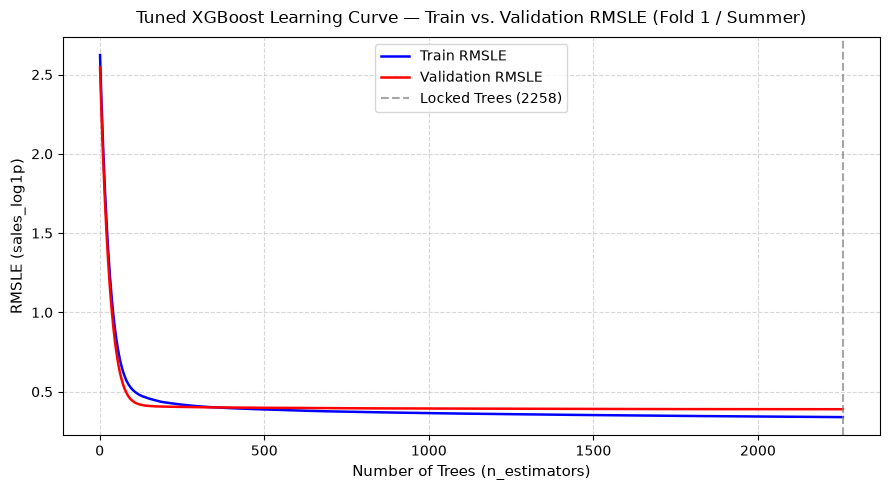

In [11]:
def plot_learning_curve(df: pd.DataFrame, model_type: str = 'XGBoost') -> None:
    train_rmse = df['train_rmse'].tolist()
    val_rmse = df['val_rmse'].tolist()
    epochs = range(1, len(train_rmse) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs, train_rmse, label='Train RMSLE', color='blue', linewidth=1.8
    )
    plt.plot(
        epochs, val_rmse, label='Validation RMSLE', color='red', linewidth=1.8
    )
    plt.axvline(
        x=len(epochs),
        color='gray',
        linestyle='--',
        alpha=0.7,
        label=f'Locked Trees ({len(epochs)})',
    )

    plt.title(
        f'Tuned {model_type} Learning Curve — Train vs. Validation RMSLE (Fold 1 / Summer)',
        fontsize=12,
        pad=10,
    )
    plt.xlabel('Number of Trees (n_estimators)', fontsize=11)
    plt.ylabel('RMSLE (sales_log1p)', fontsize=11)
    plt.legend(frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Extract cached learning history
hist_df = pd.read_csv(PROCESSED_DIR / 'tuned_xgb_model_history.csv')  
plot_learning_curve(df=hist_df, model_type='XGBoost')  


### What the Learning Curve Tells Us

* **Rapid Early Learning (Trees `1` to `200`):** Both training and validation RMSLE drop steeply from `~2.50` to below `0.42` within the first `200` trees as the ensemble captures primary category, promotional, and short-term lag signals.

* **Smooth Crossover & Long-Tail Refinement (`200` to `2,258` Trees):** Because Optuna selected a lower learning rate (`0.02814`) paired with stronger column subsampling (`colsample_bytree = 0.69`) and `max_depth = 8`, the model learns more gradually than in v1.0.0. Validation RMSLE crosses training RMSLE around tree `350` and continues to edge down steadily to **`0.38936`** at tree `2,258` with zero upward divergence, confirming that the 68-feature ensemble is well-regularized.

## 8. Model Explainability (SHAP Analysis)
With 68 correlated time-series features, standard permutation importance can underestimate individual predictors when collinear lags or rolling windows substitute for one another. We therefore use **TreeSHAP** on the validation window (`2017-07-31` to `2017-08-15`) to quantify exact marginal feature contributions and inspect how the new v1.1.0 features rank against our core v1.0.0 predictors.

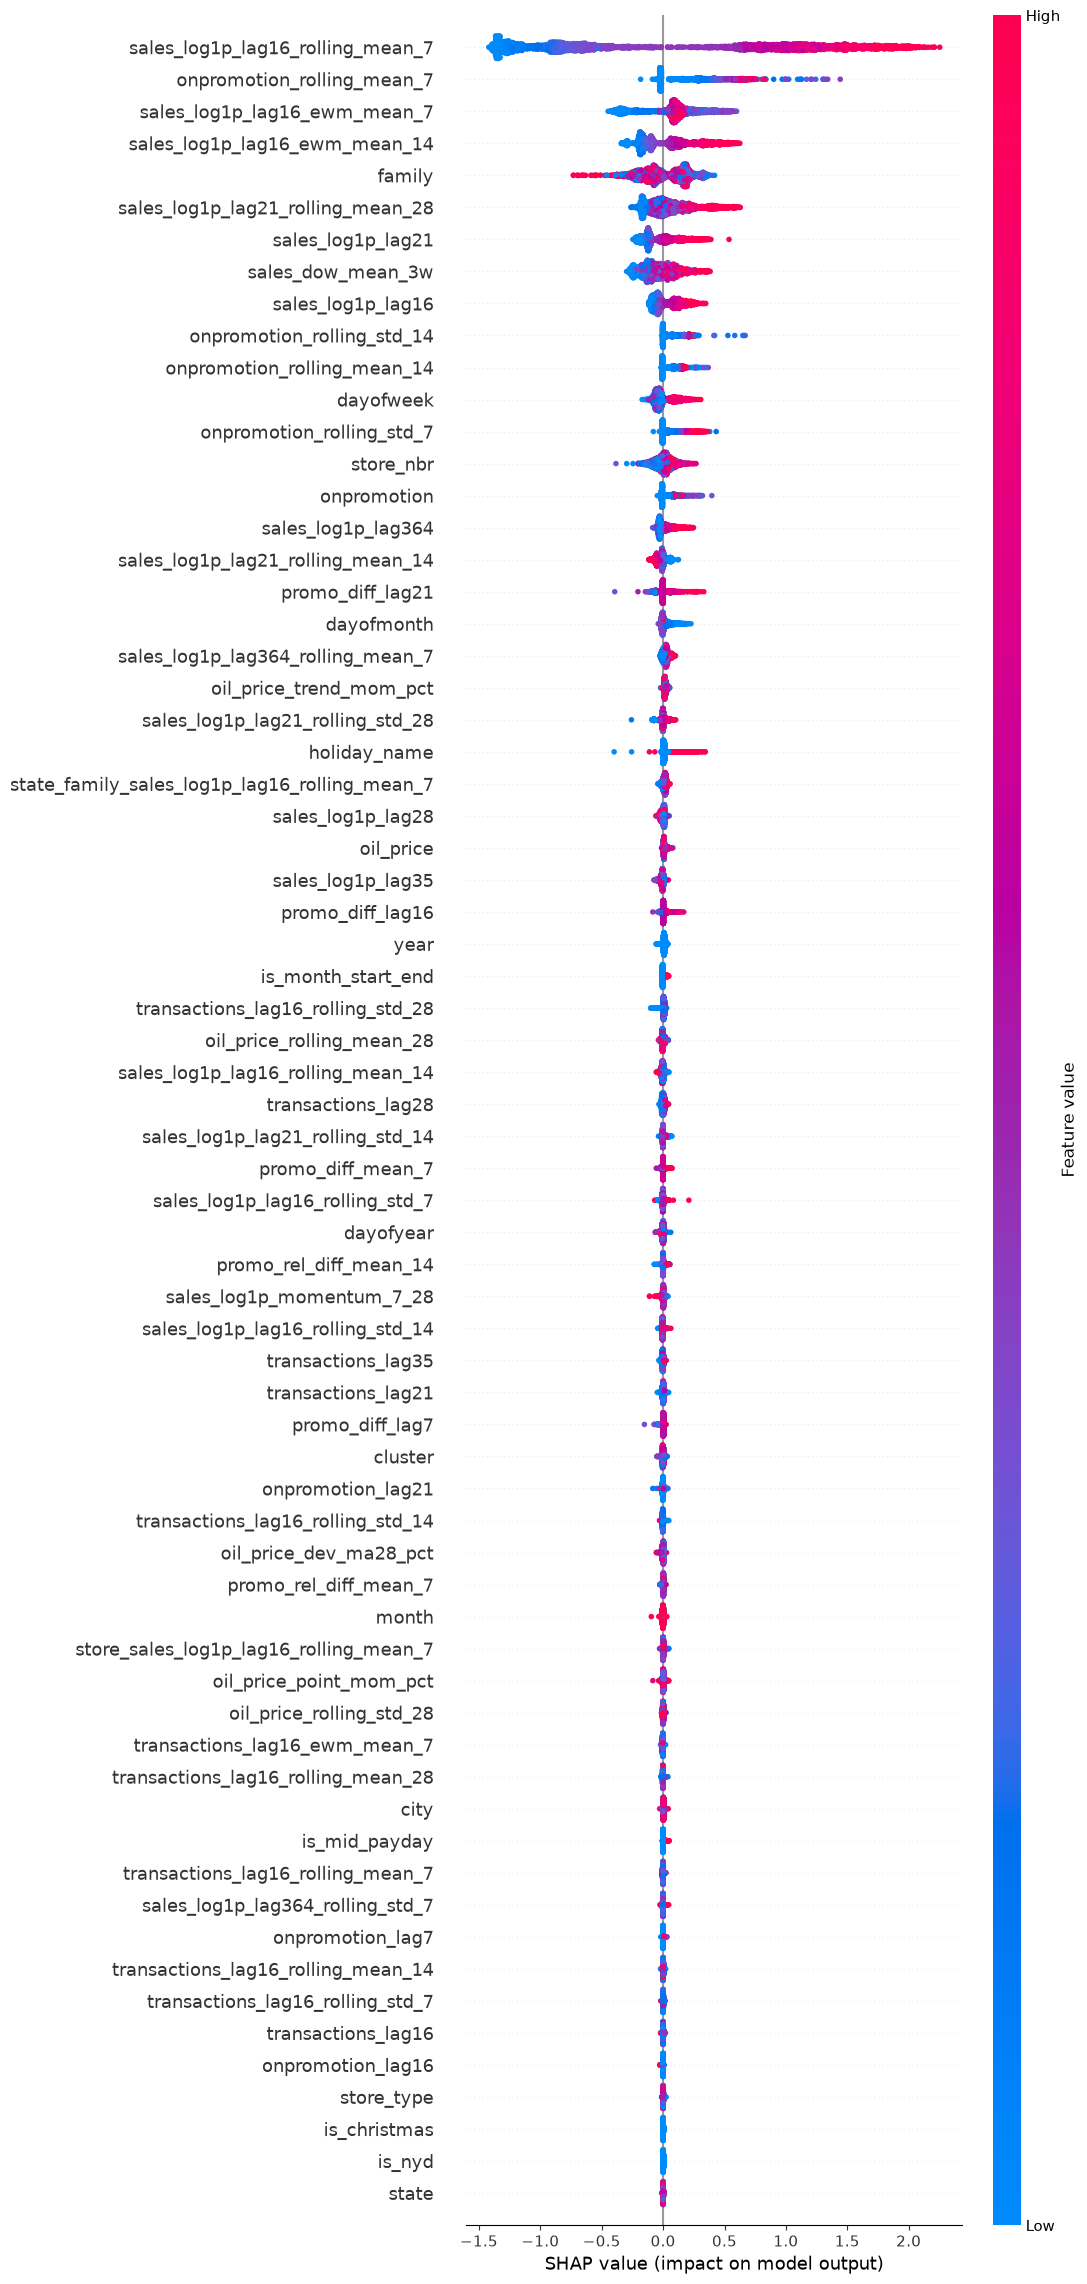

In [12]:
# Randomly choose 3000 rows from the validation set
X_sample = X_valid_full_summer.sample(3000, random_state=42)
contribs = tuned_xgb_model.get_booster().predict(
    xgb.DMatrix(X_sample, enable_categorical=True), 
    pred_contribs=True
)

# Convert category columns to numeric codes strictly for dot color-mapping in the plot
X_disp = X_sample.assign(
    **{c: X_sample[c].cat.codes for c in X_sample.select_dtypes('category')}
)
shap_values = shap.Explanation(
    values=contribs[:, :-1],
    base_values=contribs[:, -1],
    data=X_disp.values,
    feature_names=list(X_sample.columns),
)

shap.plots.beeswarm(shap_values, max_display=68) #show all features

### What the SHAP Explainability Results Tell Us

1. **New v1.1.0 Features Dominate the Top Rankings:**  
   Inspecting the global TreeSHAP ranking across all 68 features provides strong validation for our v1.1.0 feature engineering—**the top 4 predictors overall (and 7 of the top 13) are newly engineered features**:
   * **Short-Term Lag-16 Sales Anchors (`sales_log1p_lag16_rolling_mean_7` #1, `ewm_mean_7` #3, `ewm_mean_14` #4):** In v1.0.0, rolling sales averages were anchored at `lag21`, leaving a 5-day gap behind the `lag16` forecast boundary. Anchoring 7-day and 14-day rolling and exponentially weighted means directly at `lag16` provides the freshest possible demand baseline, making `sales_log1p_lag16_rolling_mean_7` the single most impactful predictor in the model (spanning $-1.5$ to $+2.2$ in log-sales space).

   * **Promotional Regime & Velocity (`onpromotion_rolling_mean_7` #2, `rolling_std_14` #10, `rolling_mean_14` #11, `rolling_std_7` #13, `promo_diff_lag21` #18):** Rather than relying solely on same-day `onpromotion` (#15), the model heavily leverages multi-week promotional intensity and promotional differentials (`promo_diff_lag21`, `promo_diff_lag16`) to distinguish isolated daily discounts from sustained promotional campaigns.

   * **Annual Seasonality & Hierarchical Context:** The new 52-week annual lags (`sales_log1p_lag364` #16 and `sales_log1p_lag364_rolling_mean_7` #20) and regional category aggregations (`state_family_sales_log1p_lag16_rolling_mean_7` #24) contribute clear, structured signal.

   * **Engineered Oil Momentum vs. Raw Oil Price:** `oil_price_trend_mom_pct` (#21) ranks higher than raw `oil_price` (#26), confirming our cross-validation finding that macroeconomic trend momentum is more informative to tree splits than raw price levels alone.

2. **Direction and Magnitude of Feature Effects:**  
   * **Demand Anchors:** High values (red dots) of short- and medium-term rolling sales (`lag16_rolling_mean_7`, `lag16_ewm_mean_7/14`, `lag21_rolling_mean_28`, `sales_dow_mean_3w`) push predictions strongly upward, while zero/low historical sales (blue clusters) pull predictions sharply downward.

   * **Promotional Catalyst:** High rolling promotion averages (`onpromotion_rolling_mean_7`) and positive promotion differentials (`promo_diff_lag21`) exhibit long positive tails to the right, acting as strong upward multipliers on predicted demand.
   
   * **Inactive Summer Flags:** Calendar indicators outside the August validation window (`is_christmas`, `is_nyd`) remain pinned at exactly $0.0$ SHAP impact, confirming clean split behavior.

**Conclusion:** The v1.1.0 feature expansion directly enriches the model's top decision splits. We now lock the XGBoost pipeline and move to our second model family: **LightGBM**.

## 9. Second Model Family: LightGBM & Optuna Tuning

To build a diverse ensemble, we pair our depth-wise **XGBoost** model with **LightGBM**, which grows trees **leaf-wise (best-first)**. We keep `max_depth = -1` (unlimited) so `num_leaves` and `min_child_samples` directly govern tree topology, allowing LightGBM to form asymmetric interaction branches whose residual errors complement XGBoost when blended.

Carrying forward our locked 68-feature set (**`ALL_FEATURES`**), we execute a 3-step pipeline:
1. **Baseline LightGBM Model:** Train a default `LGBMRegressor` (`num_leaves = 31`, `learning_rate = 0.05`) on Fold 1 (`2017-07-31` to `2017-08-15`).

2. **Bayesian Hyperparameter Tuning (Optuna):** Jointly optimize `num_leaves` (`[31, 255]`), `min_child_samples` (`[10, 200]`), `learning_rate` (`[0.025, 0.08]`), `subsample`, `colsample_bytree`, and L1/L2 penalties across **30 trials** (`6` startup trials).

3. **4-Fold Seasonal Cross-Validation:** Verify generalization across all 4 seasonal windows and lock in `FINAL_LGBM_PARAMS`.

In [13]:
def train_evaluate_lightgbm(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_valid: pd.DataFrame,
    y_valid: pd.Series,
    params: dict = None,
    verbose: int = 50,
    model_path: Path = None,
) -> tuple[lgb.LGBMRegressor, float, pd.Series]:
    """Train (or load from disk) a LightGBM regressor and evaluate validation RMSLE."""

    history_path = (
        model_path.with_name(f'{model_path.stem}_history.csv')
        if model_path
        else None
    )

    # --- 1. CASE: CACHE EXISTS (Load model + learning history & replay exact console logs) ---
    if model_path and model_path.exists() and history_path.exists():
        print(f'Loading cached model from {model_path}...\n')
        
        booster = lgb.Booster(model_file=str(model_path))

        hist_df = pd.read_csv(history_path)
        train_rmse_list = hist_df['train_rmse'].tolist()
        val_rmse_list = hist_df['val_rmse'].tolist()
        best_iter = int(hist_df['best_iteration'].iloc[0])

        if verbose:
            step = int(verbose) if isinstance(verbose, int) and verbose > 0 else 50
            for i in range(1, len(train_rmse_list) + 1):
                if i % step == 0 or i == len(train_rmse_list):
                    print(
                        f"[{i}]\tvalidation_0's rmse: {train_rmse_list[i-1]:.5f}\tvalidation_1's rmse: {val_rmse_list[i-1]:.5f}"
                    )

        raw_preds = booster.predict(X_valid, num_iteration=best_iter)

        model = lgb.LGBMRegressor()
        model._Booster = booster
        model._best_iteration = best_iter

    # --- 2. CASE: NO CACHE (Train from scratch and save both model & history) ---
    else:
        default_config = {
            'objective': 'regression',
            'random_state': 42,
            'n_jobs': 3,
            'n_estimators': 2500,
            'learning_rate': 0.05,
            'early_stopping_rounds': 50,
            'metric': 'rmse',
            'max_depth': -1,
            'num_leaves': 31,
            'min_child_samples': 20,
            'subsample': 1.0,
            'subsample_freq': 1, # enable subsample and apply it to every tree
            'colsample_bytree': 1.0,
            'reg_alpha': 0.0,
            'reg_lambda': 0.0,
            'verbosity': -1,
        }

        if params:
            default_config.update(params)

        early_stop_rounds = default_config.pop('early_stopping_rounds', None)

        model = lgb.LGBMRegressor(**default_config)

        callbacks = []
        if early_stop_rounds is not None:
            callbacks.append(
                lgb.early_stopping(stopping_rounds=early_stop_rounds, verbose=False)
            )
        if verbose and verbose > 0:
            callbacks.append(lgb.log_evaluation(period=verbose))

        model.fit(
            X_train,
            y_train,
            eval_X=(X_train, X_valid),
            eval_y=(y_train, y_valid),
            eval_names=['validation_0', 'validation_1'],
            eval_metric='rmse',
            callbacks=callbacks,
        )

        evals_res = model.evals_result_
        train_rmse_list = evals_res['validation_0']['rmse']
        val_rmse_list = evals_res['validation_1']['rmse']
        best_iter = getattr(model, 'best_iteration_', None)
        if not best_iter:
            best_iter = len(train_rmse_list)

        if model_path:
            os.makedirs(model_path.parent, exist_ok=True)
            model.booster_.save_model(str(model_path))
            pd.DataFrame({
                'train_rmse': train_rmse_list,
                'val_rmse': val_rmse_list,
                'best_iteration': best_iter,
            }).to_csv(history_path, index=False)
            print(f'Model and its history saved to {model_path}')

        raw_preds = model.predict(X_valid, num_iteration=best_iter)

    preds_valid = pd.Series(
        np.clip(raw_preds, 0, None),
        index=X_valid.index,
        name='preds_log1p',
    )

    val_rmsle = root_mean_squared_error(y_valid, preds_valid)

    if verbose:
        has_es = best_iter < len(train_rmse_list)
        iter_label = (
            f'Best Iteration: {best_iter}' if has_es else f'Total Trees: {len(train_rmse_list)}'
        )
        print(f'\n--- Validation RMSLE: {val_rmsle:.5f} ({iter_label}) ---')

    return model, val_rmsle, preds_valid


# Train (or load) Baseline LightGBM model on Fold 1 with the 68 FEATURES

baseline_lgbm_model, baseline_lgbm_rmsle, baseline_lgbm_preds = train_evaluate_lightgbm(
    X_train=X_train_full_summer,
    y_train=y_train_full_summer,
    X_valid=X_valid_full_summer,
    y_valid=y_valid_full_summer,
    verbose=50,
    model_path=PROCESSED_DIR / 'baseline_lgbm_model.json',
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/experiments/baseline_lgbm_model.json...

[50]	validation_0's rmse: 0.60684	validation_1's rmse: 0.49275
[100]	validation_0's rmse: 0.49004	validation_1's rmse: 0.43123
[150]	validation_0's rmse: 0.45805	validation_1's rmse: 0.42611
[200]	validation_0's rmse: 0.44049	validation_1's rmse: 0.42438
[250]	validation_0's rmse: 0.42909	validation_1's rmse: 0.42244
[300]	validation_0's rmse: 0.42188	validation_1's rmse: 0.41881
[350]	validation_0's rmse: 0.41478	validation_1's rmse: 0.41722
[400]	validation_0's rmse: 0.40978	validation_1's rmse: 0.41489
[450]	validation_0's rmse: 0.40590	validation_1's rmse: 0.41099
[500]	validation_0's rmse: 0.40219	validation_1's rmse: 0.40839
[550]	validation_0's rmse: 0.39879	validation_1's rmse: 0.40635
[600]	validation_0's rmse: 0.39594	validation_1's rmse: 0.40479
[650]	validation_0's rmse: 0.39334	validation_1's rmse: 0.40370
[700]	validation_0's rmse: 0.39104	valida

In [14]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna_tuning_lightgbm(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    feature_cols: list[str] = ALL_FEATURES,
    n_trials: int = 25,
    n_startup_trials: int = 5,
    seed: int = 42,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict, float]:
    """Runs hyperparameter tuning using Optuna across specified CV fold(s).
    Evaluates the Mean RMSLE across the given fold(s). Caches all trials to a CSV
    file so subsequent notebook runs replay instantly without retraining.
    """
    csv_path = output_dir / 'optuna_study_results_lgbm.csv'
    os.makedirs(output_dir, exist_ok=True)

    # --- 1. CASE: CACHE EXISTS (Instant Replay) ---
    if csv_path.exists():
        print(
            f'Found cached Optuna results in {csv_path}. Loading without retraining...\n'
        )
        study_df = pd.read_csv(csv_path)

        print(
            f'Replaying {len(study_df)} cached trials for folds: {list(cv_windows.keys())}...\n'
        )
        
        for _, row in study_df.iterrows():
            print(
                f"Trial {int(row['trial_number']):02d} | "
                f"lr: {row['learning_rate']:.5f}, leaves: {int(row['num_leaves'])}, "
                f"min_child: {int(row['min_child_samples']):3d}, "
                f"sub: {row['subsample']:.5f}, col: {row['colsample_bytree']:.5f}, "
                f"reg_alpha: {row['reg_alpha']:.5f}, reg_lambda: {row['reg_lambda']:.5f} | "
                f"Mean Val RMSLE: {row['val_rmsle']:.5f}"
            )

        best_row = study_df.loc[study_df['val_rmsle'].idxmin()]
        best_value = best_row['val_rmsle']

        param_keys = [
            'learning_rate',
            'num_leaves',
            'min_child_samples',
            'subsample',
            'colsample_bytree',
            'reg_alpha',
            'reg_lambda',
        ]

        best_params = best_row[param_keys].to_dict()
        best_params['num_leaves'] = int(best_params['num_leaves'])
        best_params['min_child_samples'] = int(best_params['min_child_samples'])

        print(f'\n--- Best Mean Val RMSLE: {best_value:.5f} ---')
        print('Best Hyperparameters:')
        for k, v in best_params.items():
            print(f'  {k}: {v}')

        return study_df, best_params, best_value

    # --- 2. PRE-SPLIT DATASETS (One-off pre-processing to avoid splitting inside the loop) ---
    print(
        f'Pre-splitting datasets for {len(cv_windows)} fold(s) to optimize memory...'
    )

    fold_datasets = {}
    for fold_name, start_date in cv_windows.items():
        X_tr, y_tr, X_val, y_val = split_train_dataset(
            df=df,
            feature_cols=feature_cols,
            target_col='sales_log1p',
            val_start=start_date,
            val_days=16,
        )
        fold_datasets[fold_name] = (X_tr, y_tr, X_val, y_val)

    # --- 3. OBJECTIVE FUNCTION ---
    def objective(trial: optuna.Trial) -> float:
        params = {
            'n_estimators': 3500,
            'learning_rate': trial.suggest_float('learning_rate', 0.025, 0.08, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 31, 255),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 200, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'subsample_freq': 1,
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        }

        fold_scores = []
        # Loop over all requested folds and evaluate
        for _, (X_tr, y_tr, X_val, y_val) in fold_datasets.items():
            model, val_score, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=params,
                verbose=0,
            )
            fold_scores.append(val_score)
            del model
            gc.collect()

        mean_val_rmsle = float(np.mean(fold_scores))

        print(
            f'Trial {trial.number + 1:02d} | '
            f"lr: {params['learning_rate']:.5f}, leaves: {params['num_leaves']}, "
            f"min_child: {params['min_child_samples']:3d}, "
            f"sub: {params['subsample']:.5f}, col: {params['colsample_bytree']:.5f}, "
            f"reg_alpha: {params['reg_alpha']:.5f}, reg_lambda: {params['reg_lambda']:.5f} | "
            f'Mean Val RMSLE: {mean_val_rmsle:.5f}'
        )

        return mean_val_rmsle

    # --- 4. RUN OPTUNA STUDY ---
    print(
        f'\nStarting Optuna Study ({n_trials} trials, {n_startup_trials} startup trials) across {len(cv_windows)} fold(s)...\n'
    )

    db_url = f"sqlite:///{output_dir}/optuna_lgbm_study.db"
    sampler = optuna.samplers.TPESampler(seed=seed, n_startup_trials=n_startup_trials)
    study = optuna.create_study(
        study_name='lgbm_tuning',
        storage=db_url,
        load_if_exists=True,
        direction='minimize', 
        sampler=sampler
    )
    trials_to_run = max(0, n_trials - len(study.trials))
    if trials_to_run > 0:
        study.optimize(objective, n_trials=trials_to_run)

    # --- 5. EXPORT RESULTS TO CSV ---
    results = []
    for t in study.trials:
        if t.state.name == 'COMPLETE':
            row = {'trial_number': t.number + 1, 'val_rmsle': t.value}
            row.update(t.params)
            results.append(row)

    study_df = pd.DataFrame(results)
    study_df.to_csv(csv_path, index=False)
    print(f'\nOptuna study results successfully saved to {csv_path}')

    print(f'\n--- Best Mean Val RMSLE: {study.best_value:.5f} ---')
    print('Best Hyperparameters:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    return study_df, study.best_params, study.best_value



TUNING_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
    #'Fold 2 (Spring / Easter)': '2017-04-05',
    #'Fold 3 (Winter / Christmas)': '2016-12-19',
    #'Fold 4 (Autumn / Regular)': '2016-09-01' 
}

lgbm_study_df, lgbm_best_params, lgbm_best_rmsle = run_optuna_tuning_lightgbm(
    df=df_train_features,
    cv_windows=TUNING_WINDOWS,
    feature_cols=ALL_FEATURES,
    n_trials=30,
    n_startup_trials=6,
    seed=42,
    output_dir=PROCESSED_DIR
)

Found cached Optuna results in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/optuna_study_results_lgbm.csv. Loading without retraining...

Replaying 30 cached trials for folds: ['Fold 1 (Summer Baseline)']...

Trial 01 | lr: 0.03865, leaves: 244, min_child:  89, sub: 0.79933, col: 0.57801, reg_alpha: 0.00421, reg_lambda: 0.00171 | Mean Val RMSLE: 0.39005
Trial 02 | lr: 0.06847, leaves: 166, min_child:  82, sub: 0.51029, col: 0.98495, reg_alpha: 2.13683, reg_lambda: 0.00707 | Mean Val RMSLE: 0.39425
Trial 03 | lr: 0.03089, leaves: 72, min_child:  24, sub: 0.76238, col: 0.71597, reg_alpha: 0.01462, reg_lambda: 0.28016 | Mean Val RMSLE: 0.39331
Trial 04 | lr: 0.02940, leaves: 96, min_child:  29, sub: 0.72803, col: 0.89259, reg_alpha: 0.00629, reg_lambda: 0.11401 | Mean Val RMSLE: 0.39212
Trial 05 | lr: 0.04980, leaves: 41, min_child:  61, sub: 0.58526, col: 0.53253, reg_alpha: 6.24514, reg_lambda: 7.28665 | Mean Val RMSLE: 0.39419
Trial 06 | lr: 0.06402, leaves:

In [15]:
def evaluate_tuned_lightgbm_cv(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    best_params: dict,
    feature_cols: list[str] = ALL_FEATURES,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict]:
    """
    Runs 4-Fold CV for both Baseline LightGBM (default parameters) and tuned LightGBM (Optuna best parameters), compares them directly, and caches the results to CSV for instant replay.
    """
    csv_path = output_dir / 'lgbm_cv_comparison_results.csv'
    os.makedirs(output_dir, exist_ok=True)

    if csv_path.exists():
        print(f'Found cached CV comparison results in {csv_path}. Loading...\n')
        comp_df = pd.read_csv(csv_path)

        print('Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...\n')
        for _, row in comp_df.iterrows():
            print(
                f"{row['fold']:<28} | Base RMSLE: {row['Baseline RMSLE']:.5f} | Tuned RMSLE: {row['Tuned RMSLE']:.5f} | Best Iter (tuned): {int(row['best_iteration'])}"
            )
        print()

    else:
        print('Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...\n')
        eval_params = {'n_estimators': 3500, **best_params}

        records = []
        for fold_name, start_date in cv_windows.items():
            X_tr, y_tr, X_val, y_val = split_train_dataset(
                df=df,
                feature_cols=feature_cols,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16,
            )

            _, base_rmsle, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=None,
                verbose=0,
            )
            
            tuned_model, tuned_rmsle, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=eval_params,
                verbose=0,
            )

            best_iter = int(getattr(tuned_model, 'best_iteration_', None) or eval_params['n_estimators'])
            print(
                f'{fold_name:<28} | Base RMSLE: {base_rmsle:.5f} | Tuned RMSLE: {tuned_rmsle:.5f} | Best Iter (tuned): {best_iter}'
            )

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'Baseline RMSLE': base_rmsle,
                'Tuned RMSLE': tuned_rmsle,
                'best_iteration': best_iter,
            })

        comp_df = pd.DataFrame(records)
        comp_df['Delta'] = comp_df['Tuned RMSLE'] - comp_df['Baseline RMSLE']
        comp_df['Improv (%)'] = ((comp_df['Delta'] / comp_df['Baseline RMSLE']) * 100).round(2)
        comp_df.to_csv(csv_path, index=False)
        print(f'\nSaved CV comparison results to {csv_path}\n')


    print('=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===')
    print(comp_df.to_string(index=False))
    print('-' * 75)
    print(
        f"Mean Baseline RMSLE : {comp_df['Baseline RMSLE'].mean():.5f}\n"
        f"Mean Tuned RMSLE    : {comp_df['Tuned RMSLE'].mean():.5f} "
        f"({comp_df['Delta'].mean():+.5f})"
    )

    # --- EXTRACT FINAL PRODUCTION PARAMETERS ---
    fold1_best_iter = int(comp_df.loc[0, 'best_iteration'])

    final_lightgbm_params = {
        'n_estimators': fold1_best_iter,
        'max_depth': -1,
        'subsample_freq': 1,
        **best_params,
    }

    print('\n=== Final Locked LightGBM Parameters (Production Ready) ===')
    for k, v in final_lightgbm_params.items():
        if isinstance(v, float):
            print(f'  {k:<18}: {v:.5f}')
        else:
            print(f'  {k:<18}: {v}')

    return comp_df, final_lightgbm_params


lgbm_cv_comparison_df, FINAL_LGBM_PARAMS = evaluate_tuned_lightgbm_cv(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    best_params=lgbm_best_params,
    feature_cols=ALL_FEATURES,
    output_dir=PROCESSED_DIR,
)

Found cached CV comparison results in /home/user/myprojects/store-sales-forecasting/data/processed/experiments/lgbm_cv_comparison_results.csv. Loading...

Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...

Fold 1 (Summer Baseline)     | Base RMSLE: 0.39788 | Tuned RMSLE: 0.38821 | Best Iter (tuned): 1359
Fold 2 (Spring / Easter)     | Base RMSLE: 0.44547 | Tuned RMSLE: 0.44029 | Best Iter (tuned): 1928
Fold 3 (Winter / Christmas)  | Base RMSLE: 1.22812 | Tuned RMSLE: 0.98821 | Best Iter (tuned): 277
Fold 4 (Autumn / Back-to-School) | Base RMSLE: 0.55568 | Tuned RMSLE: 0.52780 | Best Iter (tuned): 585

=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===
                            fold  val_start  Baseline RMSLE  Tuned RMSLE  best_iteration     Delta  Improv (%)
        Fold 1 (Summer Baseline) 2017-07-31        0.397884     0.388212            1359 -0.009673       -2.43
        Fold 2 (Spring / Easter) 2017-04-05        0.445470     0.440293            1928 -

### What the LightGBM Cross-Validation Results Tell Us

1. **Best Standalone Accuracy on the Target Horizon (`0.38821`):**  
   On Fold 1 (Summer), Optuna tuning reduces LightGBM validation RMSLE from `0.39788` (baseline) to **`0.38821` (`-2.43%`)** at `1,359` trees. This improves upon our v1.0.0 tuned LightGBM model (`0.39202`) by `-0.00381` RMSLE and edges out our v1.1.0 tuned XGBoost model (`0.38935`).

2. **Consistent Gains Across All 4 Seasonal Folds:**  
   Unlike v1.0.0—where aggressive leaf-wise growth (`num_leaves = 235`, `min_child_samples = 11`) showed higher sensitivity during the Autumn transition—our v1.1.0 tuned LightGBM model improves upon its untuned baseline across **all 4 seasonal folds**, reducing 4-fold mean RMSLE from `0.65679` to **`0.58613` (`-0.07066`)**:
   * **Fold 1 (Summer):** `0.39788` $\rightarrow$ **`0.38821` (`-2.43%`)**

   * **Fold 2 (Spring / Easter):** `0.44547` $\rightarrow$ **`0.44029` (`-1.16%`)**

   * **Fold 3 (Winter / Christmas):** `1.22812` $\rightarrow$ **`0.98821` (`-19.53%`)**
   
   * **Fold 4 (Autumn / Back-to-School):** `0.55568` $\rightarrow$ **`0.52780` (`-5.02%`)** — achieving our lowest error yet on the challenging September transition (outperforming tuned XGBoost's `0.55198`).

3. **Why Leaf-Wise Regularization Succeeded on 68 Features:**  
   To handle the doubled feature space without overfitting correlated lags, Optuna paired a moderately expressive leaf capacity (`num_leaves = 159`) with a much stricter minimum leaf size (**`min_child_samples = 79`** vs. `11` in v1.0.0) and feature subsampling (`colsample_bytree = 0.69384`). This prevented noisy splits on small leaf nodes while allowing asymmetric trees to exploit our new 7-day rolling/EWM and promotional velocity features.

## 10. Tuned LightGBM Model & Learning Curve
We now train our final validation **LightGBM** model on Fold 1 (`2017-07-31` to `2017-08-15`) using all 68 features (`ALL_FEATURES`) and `FINAL_LGBM_PARAMS` (`n_estimators = 1359`), and inspect its learning curve to verify convergence stability.

In [16]:
tuned_lgbm_model, tuned_lgbm_rmsle, tuned_lgbm_preds_valid = train_evaluate_lightgbm(
    X_train=X_train_full_summer, 
    y_train=y_train_full_summer, 
    X_valid=X_valid_full_summer, 
    y_valid=y_valid_full_summer, 
    params={**FINAL_LGBM_PARAMS, 'early_stopping_rounds': None}, 
    verbose=0,
    model_path=PROCESSED_DIR / 'tuned_lgbm_model.json'
)

print(
    f"Tuned LightGBM (Validation / Fold 1) | Trees: {FINAL_LGBM_PARAMS['n_estimators']} | Validation RMSLE: {tuned_lgbm_rmsle:.5f}"
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/experiments/tuned_lgbm_model.json...

Tuned LightGBM (Validation / Fold 1) | Trees: 1359 | Validation RMSLE: 0.38821


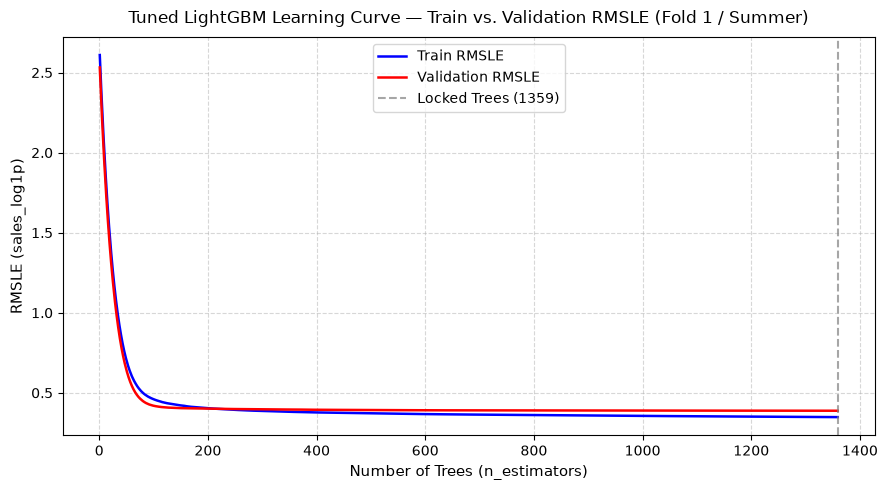

In [17]:
hist_df = pd.read_csv(PROCESSED_DIR / 'tuned_lgbm_model_history.csv')  
plot_learning_curve(df=hist_df, model_type='LightGBM') 

### What the LightGBM Learning Curve Tells Us

* **Fast Convergence & Flat Validation Plateau (`1,359` Trees):** Validation RMSLE drops steeply below `0.42` within the first `150` trees, crosses the training curve around tree `220`, and glides smoothly to **`0.38821`** at tree `1,359` with zero upward drift.

* **Tight Generalization Gap:** Enforcing `min_child_samples = 79` and `colsample_bytree = 0.69384` alongside `num_leaves = 159` keeps the training-to-validation gap remarkably narrow across all `1,359` iterations, confirming that the leaf-wise ensemble is well-regularized across the 68-feature space.

## 11. Model Ensembling (XGBoost + LightGBM Blend)

In our final modeling step, we combine the validation predictions of our tuned depth-wise **XGBoost** (`0.38936`) and leaf-wise **LightGBM** (`0.38821`) models on Fold 1 (`2017-07-31` to `2017-08-15`).

Since our evaluation metric (RMSLE) is RMSE in `log1p` space, we compute a weighted linear combination directly on the log-transformed predictions:

$$\hat{y}_{\text{blend}} = w \cdot \hat{y}_{\text{LGBM}} + (1 - w) \cdot \hat{y}_{\text{XGB}}, \quad w \in [0, 1]$$

We sweep $w$ from `0.00` (100% XGBoost) to `1.00` (100% LightGBM) in steps of `0.01` to find the optimal ensemble weights and summarize all modeling milestones.

Tuned XGBoost Standalone RMSLE  : 0.38936 (Weight: 0.00 LGBM / 1.00 XGB)
Tuned LightGBM Standalone RMSLE : 0.38821 (Weight: 1.00 LGBM / 0.00 XGB)
Equal 50/50 Blend RMSLE         : 0.38768 (Weight: 0.50 LGBM / 0.50 XGB)
Optimal Weighted Blend RMSLE    : 0.38761 (Weight: 0.63 LGBM / 0.37 XGB)



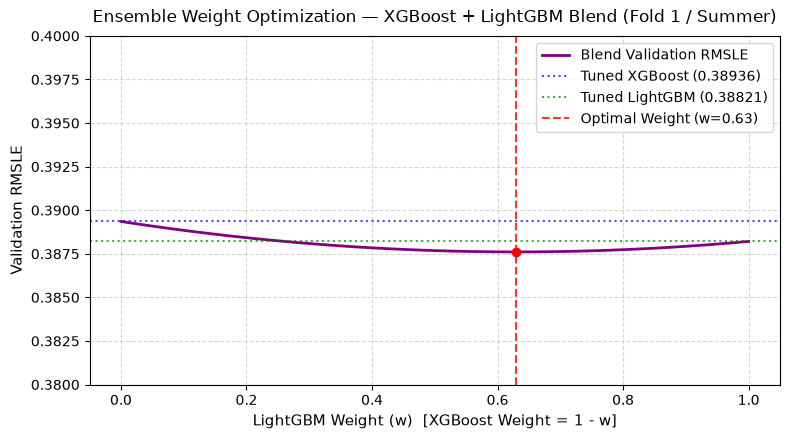

In [18]:
# Sweep ensemble weights w in [0, 1] for LightGBM and (1 - w) for XGBoost
weights = np.linspace(0, 1, 101)
blend_rmsles = []

for w in weights:
    blend_preds = (w * tuned_lgbm_preds_valid) + ((1 - w) * tuned_xgb_preds_valid)
    score = root_mean_squared_error(y_valid_full_summer, blend_preds)
    blend_rmsles.append(score)

best_idx = int(np.argmin(blend_rmsles))
BEST_LGBM_WEIGHT = float(weights[best_idx])
BEST_XGB_WEIGHT = round(1.0 - BEST_LGBM_WEIGHT, 2)
best_blend_rmsle = float(blend_rmsles[best_idx])

# Also evaluate a simple 50/50 equal-weight blend
equal_blend_preds = 0.50 * tuned_lgbm_preds_valid + 0.50 * tuned_xgb_preds_valid
equal_blend_rmsle = root_mean_squared_error(y_valid_full_summer, equal_blend_preds)

print(f'Tuned XGBoost Standalone RMSLE  : {tuned_xgb_rmsle:.5f} (Weight: 0.00 LGBM / 1.00 XGB)')
print(f'Tuned LightGBM Standalone RMSLE : {tuned_lgbm_rmsle:.5f} (Weight: 1.00 LGBM / 0.00 XGB)')
print(f'Equal 50/50 Blend RMSLE         : {equal_blend_rmsle:.5f} (Weight: 0.50 LGBM / 0.50 XGB)')
print(f'Optimal Weighted Blend RMSLE    : {best_blend_rmsle:.5f} (Weight: {BEST_LGBM_WEIGHT:.2f} LGBM / {BEST_XGB_WEIGHT:.2f} XGB)\n')

# --- PLOT ENSEMBLE WEIGHT OPTIMIZATION CURVE ---
plt.figure(figsize=(8, 4.5))
plt.plot(weights, blend_rmsles, color='purple', linewidth=2, label='Blend Validation RMSLE')
plt.axhline(tuned_xgb_rmsle, color='blue', linestyle=':', alpha=0.7, label=f'Tuned XGBoost ({tuned_xgb_rmsle:.5f})')
plt.axhline(tuned_lgbm_rmsle, color='green', linestyle=':', alpha=0.7, label=f'Tuned LightGBM ({tuned_lgbm_rmsle:.5f})')
plt.axvline(BEST_LGBM_WEIGHT, color='red', linestyle='--', alpha=0.8, label=f'Optimal Weight (w={BEST_LGBM_WEIGHT:.2f})')
plt.scatter([BEST_LGBM_WEIGHT], [best_blend_rmsle], color='red', zorder=5)

plt.title('Ensemble Weight Optimization — XGBoost + LightGBM Blend (Fold 1 / Summer)', fontsize=12, pad=10)
plt.xlabel('LightGBM Weight (w)  [XGBoost Weight = 1 - w]', fontsize=11)
plt.ylabel('Validation RMSLE', fontsize=11)
plt.ylim(0.38, 0.40)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [19]:
# --- FINAL MILESTONE SUMMARY TABLE ---
trimmed_xgb_rmsle = float(
    cv_df.loc[
        (cv_df['fold'] == 'Fold 1 (Summer Baseline)') & (cv_df['configuration'].str.contains('Trimmed')),
        'val_rmsle'
    ].iloc[0]
)

final_summary_df = pd.DataFrame([
    {'Model Stage': '1. Baseline XGBoost (All 68 Features)', 'Features': 68, 'Trees': 1142, 'Val RMSLE (Fold 1)': baseline_rmsle},
    {'Model Stage': '2. Baseline LightGBM (All 68 Features)', 'Features': 68, 'Trees': 1067, 'Val RMSLE (Fold 1)': baseline_lgbm_rmsle},
    {'Model Stage': '3. Tuned XGBoost (Optuna)', 'Features': 68, 'Trees': FINAL_XGB_PARAMS['n_estimators'], 'Val RMSLE (Fold 1)': tuned_xgb_rmsle},
    {'Model Stage': '4. Tuned LightGBM (Optuna)', 'Features': 68, 'Trees': FINAL_LGBM_PARAMS['n_estimators'], 'Val RMSLE (Fold 1)': tuned_lgbm_rmsle},
    {'Model Stage': '5. Equal Blend (50% LGBM + 50% XGB)', 'Features': 68, 'Trees': '-', 'Val RMSLE (Fold 1)': equal_blend_rmsle},
    {'Model Stage': f'6. Optimal Blend ({int(BEST_LGBM_WEIGHT*100)}% LGBM + {int(BEST_XGB_WEIGHT*100)}% XGB)', 'Features': 68, 'Trees': '-', 'Val RMSLE (Fold 1)': best_blend_rmsle},
])

display(final_summary_df.round(5))

,Model Stage,Features,Trees,Val RMSLE (Fold 1)
0,1. Baseline XGBoost (All 68 Features),68,1142,0.39469
1,2. Baseline LightGBM (All 68 Features),68,1067,0.39788
2,3. Tuned XGBoost (Optuna),68,2258,0.38936
3,4. Tuned LightGBM (Optuna),68,1359,0.38821
4,5. Equal Blend (50% LGBM + 50% XGB),68,-,0.38768
5,6. Optimal Blend (63% LGBM + 37% XGB),68,-,0.38761


### What the Ensembling Results Tell Us

* **Variance Reduction Across Tree Topologies (`0.38761`):** Blending our depth-wise **XGBoost** (`0.38936`) and leaf-wise **LightGBM** (`0.38821`) models pushes validation RMSLE down to **`0.38761`** at **`63% LightGBM + 37% XGBoost`** (`w = 0.63`), outperforming both standalone models as their structural prediction errors partially cancel out.

* **Flat, Stable Optimization Basin:** As the weight optimization curve illustrates, a simple `50/50` equal-weight average (`0.38768`) performs nearly identically to the optimal `63/37` split (`0.38761`), confirming that the ensemble gain is robust and not sensitive to fine weight tuning.

* **Cumulative Progression (v1.0.0 $\rightarrow$ v1.1.0):**  
  * **v1.0.0 Pipeline (34 $\rightarrow$ 31 Features):** Progressed from `0.40022` (Baseline) to **`0.39113`** (Final Ensemble).  
  
  * **v1.1.0 Pipeline (68 Features):** Progressed from `0.39469` (Baseline) to **`0.38761`** (Final Ensemble)—an additional **`-0.00352` RMSLE** improvement on the Summer test horizon (and **`-0.01261` RMSLE / `-3.15%`** total error reduction from our initial v1.0.0 baseline), alongside major cross-seasonal gains in Autumn (`0.52780`) and Winter open days (`0.49854`).

We now lock in our **68 engineered features (`ALL_FEATURES`)**, tuned hyperparameters (`FINAL_XGB_PARAMS`, `FINAL_LGBM_PARAMS`), and **`0.63 / 0.37` ensemble weights** for final full-dataset training and test forecasting.